In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df_1 = pd.read_csv("2001-2010.csv")
df_2 = pd.read_csv("2011-2020.csv")
df_3 = pd.read_csv("2015-2024.csv")

In [4]:
df_1.head()

,Region and country of nationality,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010
0,REGION,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Total,"68,925","26,785","28,286","52,840","53,738","41,094","48,218","60,107","74,602","73,293"
2,Africa,"19,070","2,551","10,719","29,108","20,746","18,129","17,486","8,943","9,678","13,325"
3,Asia,"16,985","7,723","6,731","12,276","15,769","10,086","23,563","44,819","58,309","52,695"
4,Europe,"29,897","14,579","10,381","7,879","10,524","9,615","4,193","2,059","1,693","1,238"


In [5]:
# Keep non-overlapping year columns
years_df2 = [
    c
    for c in df_2.columns
    if c not in df_3.columns or c == "Region and country of nationality"
]
years_df1 = [
    c
    for c in df_1.columns
    if c not in df_2.columns or c == "Region and country of nationality"
]

df_comb = df_1[years_df1].merge(
    df_2[years_df2].merge(
        df_3, on="Region and country of nationality", how="outer"
    ),
    on="Region and country of nationality",
    how="outer",
)

In [6]:
df_comb.head()

,Region and country of nationality,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Afghanistan,"2,930","1,683","1,453",959,902,651,441,576,349,...,910,"2,740","1,320",800,"1,200",600,870,"1,620","6,590","14,680"
1,Africa,"19,070","2,551","10,719","29,108","20,746","18,129","17,486","8,943","9,678",...,"22,500","31,640","20,250","10,460","16,370","4,170","6,260","11,410","24,530","34,100"
2,Algeria,31,-,4,D,D,D,-,-,-,...,0,0,0,0,0,0,0,0,0,10
3,All other countries,49,31,29,18,20,23,25,31,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,All other countries1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,60,60,60,30,30,20,30,30,40,110


C:\Users\samho\AppData\Local\Temp\ipykernel_6352\4229594567.py:108: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(left=0.32, right=0.85, top=0.90, bottom=0.16)


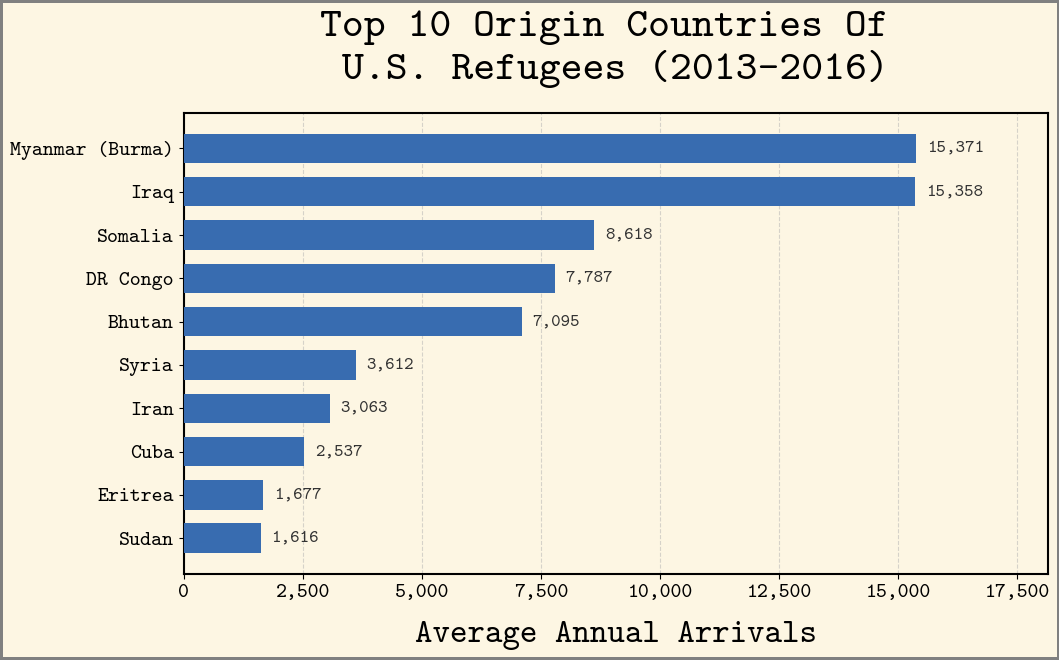

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Apply custom style
plt.style.use("btt_style")

country_col = "Region and country of nationality"

# 2. Prepare and clean data
df_work = df_comb.copy()
df_work[country_col] = df_work[country_col].astype(str).str.strip()

# 3. Filter for Obama's second term (FY 2013 to 2016)
year_cols = [
    c for c in df_work.columns if str(c).strip().isdigit() and 2013 <= int(c) <= 2016
]

for col in year_cols:
    df_work[col] = (
        df_work[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .replace({"-": "0", "D": "0"})
    )
    df_work[col] = pd.to_numeric(df_work[col], errors="coerce").fillna(0)

# Filter out regional aggregate/header rows common in DHS tables
summary_rows = [
    "Total",
    "Africa",
    "Asia",
    "Europe",
    "North America",
    "South America",
    "Oceania",
    "Unknown",
]
df_work = df_work[~df_work[country_col].isin(summary_rows)].copy()

# Clean up names for readability
name_replacements = {
    "Congo, Democratic Republic": "DR Congo",
    "Burma": "Myanmar (Burma)",
}
df_work[country_col] = df_work[country_col].replace(name_replacements)

# 4. Calculate average annual arrivals across FY 2013-2016
df_work["Annual_Average"] = df_work[year_cols].mean(axis=1)

# Group by country, take top 10, sort ascending so #1 is at top
df_top10 = (
    df_work.groupby(country_col)["Annual_Average"]
    .sum()
    .nlargest(10)
    .sort_values(ascending=True)
    .reset_index()
)

# 5. Build visualization
fig, ax = plt.subplots(figsize=(11, 7))

# Single uniform color for all bars
bar_color = "#386CB0"

bars = ax.barh(
    df_top10[country_col],
    df_top10["Annual_Average"],
    color=bar_color,
    edgecolor="none",
    height=0.68,
    zorder=3,
)

# Data labels at bar ends
max_val = df_top10["Annual_Average"].max()
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + (max_val * 0.015),
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        ha="left",
        fontsize=13,
        fontweight="bold",
        color="#333333",
    )

# Formatting & Titles
ax.set_title(
    "Top 10 Origin Countries Of \nU.S. Refugees (2013-2016)",
    pad=24,
    fontsize=30,
    fontweight="bold",
)
ax.set_xlabel("Average Annual Arrivals", labelpad=14, fontsize=24)
ax.set_xlim(0, max_val * 1.18)
ax.yaxis.set_tick_params(labelsize=15)
ax.xaxis.set_tick_params(labelsize=15)
ax.xaxis.set_major_formatter("{x:,.0f}")

# Gridlines
ax.grid(axis="x", linestyle="--", alpha=0.5, zorder=0)
ax.set_axisbelow(True)

# Spacing adjustment so labels and x-axis title aren't clipped
plt.subplots_adjust(left=0.32, right=0.85, top=0.90, bottom=0.16)

# Force outer border thickness
fig.patch.set_linewidth(4)

fig.savefig('bar.png',dpi=600)

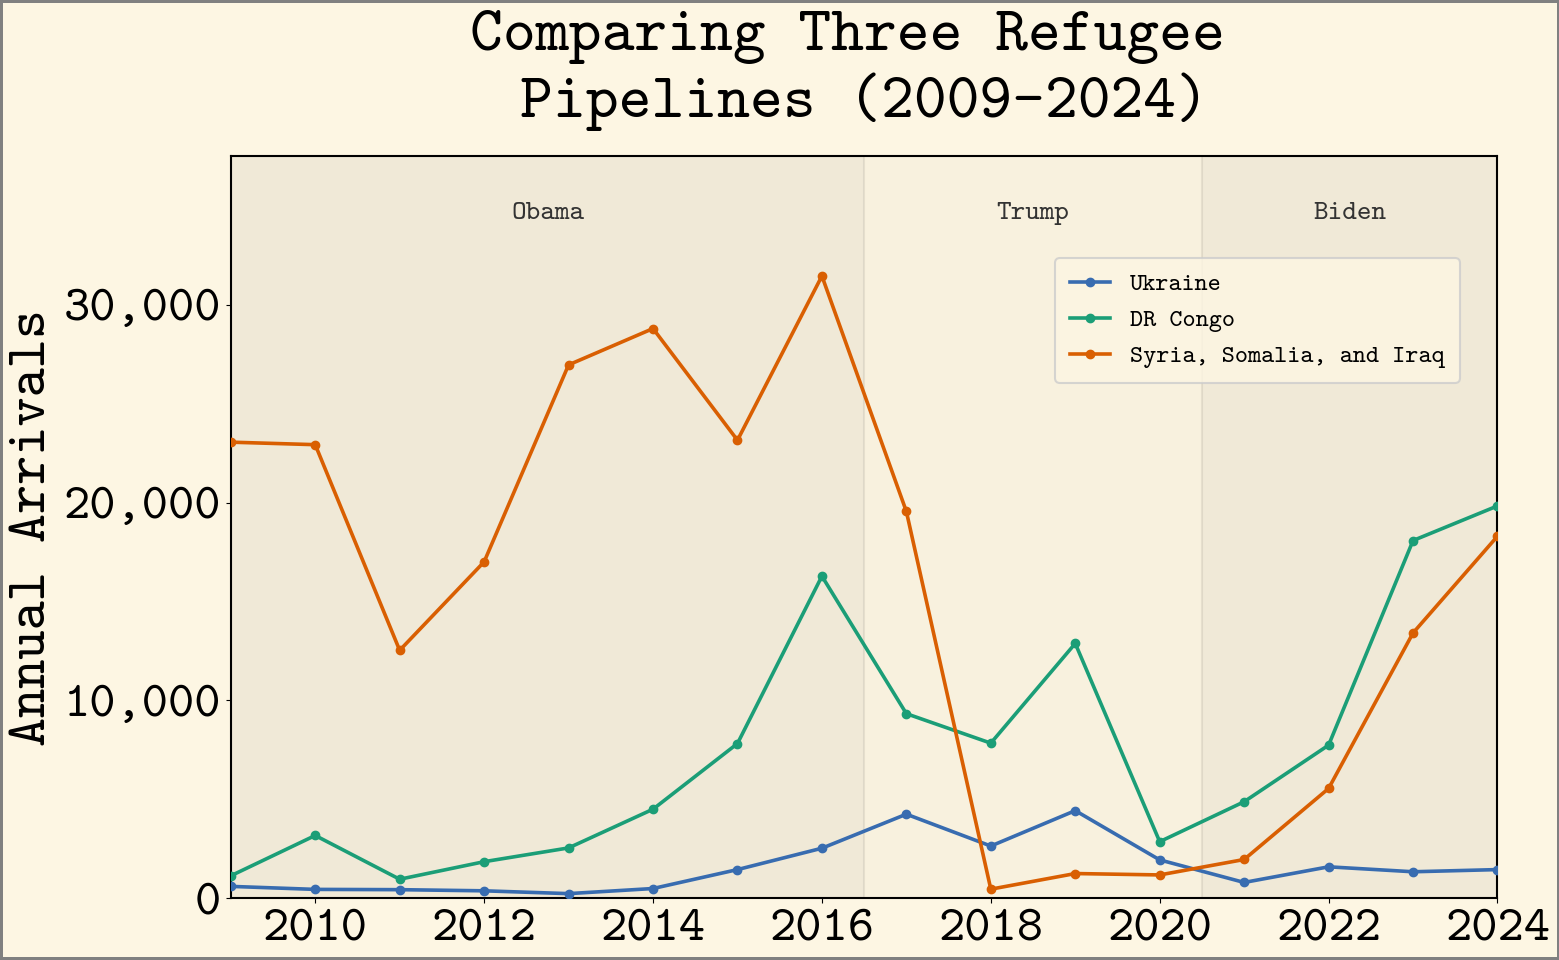

In [14]:
# 1. Apply custom style
plt.style.use("btt_style")

# 2. Define group mapping
target_mideast = ["Syria", "Iraq", "Somalia"]
country_col = "Region and country of nationality"

# Clean strings
df_work = df_comb.copy()
df_work[country_col] = df_work[country_col].astype(str).str.strip()

# Filter for the relevant countries
df_work = df_work[
    df_work[country_col].isin(
        target_mideast + ["Congo, Democratic Republic", "Ukraine"]
    )
].copy()

# 3. Clean year columns (filtering from 2009 to 2024)
year_cols = [
    c for c in df_work.columns if str(c).strip().isdigit() and int(c) >= 2009
]

for col in year_cols:
  df_work[col] = (
      df_work[col]
      .astype(str)
      .str.replace(",", "", regex=False)
      .replace({"-": "0", "D": "0"})
  )
  df_work[col] = pd.to_numeric(df_work[col], errors="coerce").fillna(0)

# 4. Map countries into simplified labels
category_map = {
    "Syria": "Syria, Somalia, and Iraq",
    "Iraq": "Syria, Somalia, and Iraq",
    "Somalia": "Syria, Somalia, and Iraq",
    "Congo, Democratic Republic": "DR Congo",
    "Ukraine": "Ukraine",
}
df_work["Category"] = df_work[country_col].map(category_map)

# Sum aggregated admissions by category
df_grouped = df_work.groupby("Category")[year_cols].sum().reset_index()

# Melt to long format
df_long = df_grouped.melt(
    id_vars=["Category"],
    value_vars=year_cols,
    var_name="Year",
    value_name="Arrivals",
)
df_long["Year"] = df_long["Year"].astype(int)

# 5. Build visualization
fig, ax = plt.subplots()

# Presidential term shading (FY 2009-2016 Obama, 2017-2020 Trump, 2021-2024 Biden)
presidencies = [
    ("Obama", 2009, 2016.5, "#000000", 0.05),
    ("Trump", 2016.5, 2020.5, "#000000", 0.02),
    ("Biden", 2020.5, 2024, "#000000", 0.05),
]

for name, start, end, color, alpha in presidencies:
  ax.axvspan(start, end, color=color, alpha=alpha, zorder=1)
  mid_point = (start + end) / 2
  ax.text(
      mid_point,
      35200,
      name,
      ha="center",
      va="top",
      fontsize=20,
      fontweight="bold",
      color="#333333",
  )

palette = {
    "Syria, Somalia, and Iraq": "#D95F02",
    "DR Congo": "#1B9E77",
    "Ukraine": "#386CB0",
}

# Explicit order for plotting and legend
display_order = ["Ukraine", "DR Congo", "Syria, Somalia, and Iraq"]

for cat in display_order:
  group = df_long[df_long["Category"] == cat]
  group_sorted = group.sort_values("Year")
  ax.plot(
      group_sorted["Year"],
      group_sorted["Arrivals"],
      marker="o",
      markersize=6,
      linewidth=2.6,
      label=cat,
      color=palette.get(cat, None),
      zorder=3,
  )

# Labels & Limits
ax.set_title("Comparing Three Refugee \nPipelines (2009-2024)", pad=28)
ax.set_ylabel("Annual Arrivals")
ax.set_xlim(2009, 2024)
ax.set_ylim(0, 37500)
ax.yaxis.set_major_formatter("{x:,.0f}")

# Legend inside upper right, lowered to clear president header labels
ax.legend(
    frameon=True,
    loc="upper right",
    bbox_to_anchor=(0.98, 0.88),
    fontsize=18,
    labelspacing=0.5,
    handlelength=1.6,
    borderpad=0.6,
)

# Force outer border thickness
fig.patch.set_linewidth(4)

plt.show()